# Data Mining. Practice 2
**Part 1.** Data Exploration, Variable Transformation, Distance, Jaccard, Cosine, Correlation
**Part 2.** Feature Selection, PCA, Kernel Functions, Outlier Analysis



**Dataset:** Adult Income Dataset (Kaggle) — https://www.kaggle.com/datasets/wenruliu/adult-income-dataset
48,842 rows, 15 columns. **Target:** `income` (`>50K` → 1, `<=50K` → 0).
- 6 numeric attributes: `age`, `fnlwgt`, `educational-num`, `capital-gain`, `capital-loss`, `hours-per-week`
- 8 categorical attributes: `workclass`, `education`, `marital-status`, `occupation`, `relationship`, `race`, `gender`, `native-country`

Setup: missing values are stored as `?` in the file, so I replace them with the category `Unknown`. To keep every task fast and reproducible, all tasks use one random sample of **5,000 rows** (`random_state=42`).

In [1]:
import numpy as np, pandas as pd, warnings
import matplotlib.pyplot as plt, seaborn as sns
from scipy.spatial.distance import pdist, squareform
from sklearn.feature_selection import mutual_info_classif, chi2
from sklearn.ensemble import RandomForestClassifier
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

# adult.csv = file downloaded from the Kaggle page above (fallback: a GitHub copy of the same file)
try:
    df_full = pd.read_csv("adult.csv")
except FileNotFoundError:
    df_full = pd.read_csv("https://raw.githubusercontent.com/saravrajavelu/Adult-Income-Analysis/master/adult.csv")

df_full = df_full.replace("?", "Unknown")
df = df_full.sample(5000, random_state=42).reset_index(drop=True)
df["target"] = (df["income"] == ">50K").astype(int)

num_cols = ["age", "fnlwgt", "educational-num", "capital-gain", "capital-loss", "hours-per-week"]
cat_cols = ["workclass", "education", "marital-status", "occupation", "relationship", "race", "gender", "native-country"]
target = "target"
print("Full dataset:", df_full.shape, "| working sample:", df.shape)
print("Share of >50K in sample:", round(df[target].mean(), 3))
df.head()

Full dataset: (48842, 15) | working sample: (5000, 16)
Share of >50K in sample: 0.24


,age,workclass,fnlwgt,education,educational-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country,income,target
0,56,Private,33115,HS-grad,9,Divorced,Other-service,Unmarried,White,Female,0,0,40,United-States,<=50K,0
1,25,Private,112847,HS-grad,9,Married-civ-spouse,Transport-moving,Own-child,Other,Male,0,0,40,United-States,<=50K,0
2,43,Private,170525,Bachelors,13,Divorced,Prof-specialty,Not-in-family,White,Female,14344,0,40,United-States,>50K,1
3,32,Private,186788,HS-grad,9,Married-civ-spouse,Transport-moving,Husband,White,Male,0,0,40,United-States,<=50K,0
4,39,Private,277886,Bachelors,13,Married-civ-spouse,Sales,Wife,White,Female,0,0,30,United-States,<=50K,0


# Part 1

## Task 1. Data Exploration
Attribute 1 = `age` (histogram, box plot, box plot algorithm). Attribute 2 = `hours-per-week` (scatter plot against `age`).

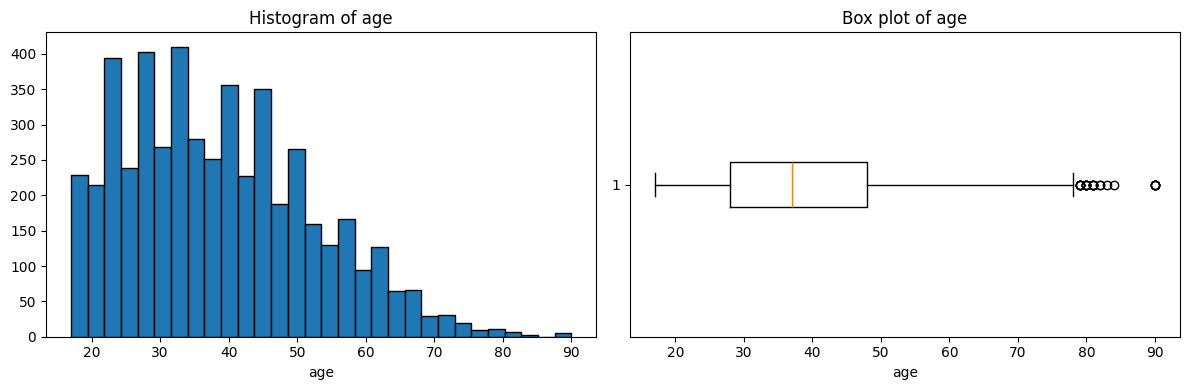

Q1 = 28.0, Q3 = 48.0, IQR = 20.0
Lower bound = Q1 - 1.5*IQR = -2.0
Upper bound = Q3 + 1.5*IQR = 78.0

Outliers detected: 24
Outlier ages: [79, 79, 79, 79, 79, 80, 80, 80, 80, 80, 81, 81, 81, 81, 81, 82, 82, 83, 84, 90, 90, 90, 90, 90]


In [2]:
col = "age"
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(df[col], bins=30, edgecolor="black"); ax[0].set_title("Histogram of age"); ax[0].set_xlabel("age")
ax[1].boxplot(df[col], vert=False); ax[1].set_title("Box plot of age"); ax[1].set_xlabel("age")
plt.tight_layout(); plt.show()

# Box plot algorithm
Q1 = df[col].quantile(0.25); Q3 = df[col].quantile(0.75); IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR; upper = Q3 + 1.5 * IQR
print(f"Q1 = {Q1}, Q3 = {Q3}, IQR = {IQR}")
print(f"Lower bound = Q1 - 1.5*IQR = {lower}")
print(f"Upper bound = Q3 + 1.5*IQR = {upper}")
outliers = df[(df[col] < lower) | (df[col] > upper)]
print(f"\nOutliers detected: {len(outliers)}")
print("Outlier ages:", sorted(outliers[col].tolist()))

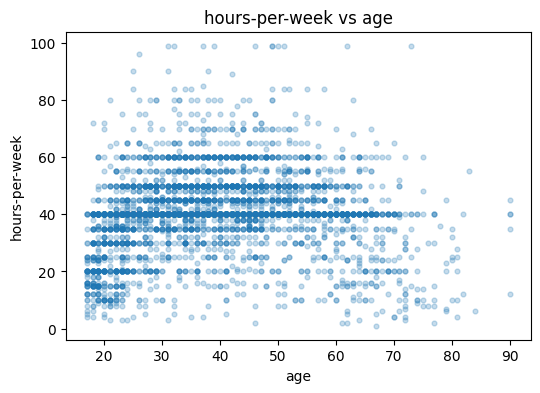

Pearson correlation age vs hours-per-week: 0.087


In [3]:
col2 = "hours-per-week"
plt.figure(figsize=(6, 4))
plt.scatter(df[col], df[col2], alpha=0.25, s=12)
plt.xlabel("age"); plt.ylabel("hours-per-week"); plt.title("hours-per-week vs age"); plt.show()
print("Pearson correlation age vs hours-per-week:", round(df[col].corr(df[col2]), 3))

**Interpretation.** Age is right-skewed (many people 25–45, a long tail to 90). Q1 = 28, Q3 = 48, IQR = 20, so the bounds are [−2, 78]; the lower bound is below any real age, so only the **upper** tail is flagged: **24 outliers**, all aged 79–90. The scatter plot of `hours-per-week` vs `age` is a broad cloud with no visible trend; the correlation is only ≈ 0.09, so the relationship is **essentially unrelated** (at most very weakly positive).

## Task 2. Variable Transformation
Attribute: `capital-gain` (strongly right-skewed: most values are 0, a few are very large).

In [4]:
col = "capital-gain"
x = df[col]
log_x    = np.log(x + 1)
minmax_x = (x - x.min()) / (x.max() - x.min())
zscore_x = (x - x.mean()) / x.std()

summary = pd.DataFrame({
    "original": x, "log(x+1)": log_x, "min-max": minmax_x, "z-score": zscore_x
}).agg(["min", "max", "mean", "std"]).T
print("Share of zeros in capital-gain:", round((x == 0).mean(), 3))
summary

Share of zeros in capital-gain: 0.912


,min,max,mean,std
original,0.000000,99999.000000,1.160680e+03,7628.741675
log(x+1),0.000000,11.512925,7.811351e-01,2.529044
min-max,0.000000,1.000000,1.160692e-02,0.076288
z-score,-0.152146,12.956045,-1.350031e-17,1.000000


**Interpretation.** The log transform shrinks the range from 0–99,999 to 0–11.5, but the values are still on a different scale from the other attributes. Min-max squeezes almost all rows near 0 (std 0.076) because one extreme value (99,999) sets the maximum. **I would use Z-score before computing distances**: every attribute gets mean 0 and std 1, so no attribute dominates the distance just because of its units, and it is less distorted by the extreme maximum than min-max.

## Task 3. Distance and Similarity Measures
Sample of 10 rows. Euclidean, Manhattan and Minkowski (p=3) are computed on the **z-scored numeric attributes** (otherwise `fnlwgt`, with values in the hundreds of thousands, would dominate). Cosine similarity uses the same z-scored numeric vectors. Jaccard similarity uses the **categorical attributes**: each row becomes a set of `attribute=value` items.

In [5]:
sample = df.sample(10, random_state=1).reset_index(drop=True)
print(sample[num_cols + cat_cols])

scaler = StandardScaler().fit(df[num_cols])
Xs = scaler.transform(sample[num_cols])

def as_df(M): return pd.DataFrame(M, index=range(10), columns=range(10)).round(3)

euclid    = squareform(pdist(Xs, "euclidean"))
manhattan = squareform(pdist(Xs, "cityblock"))
minkowski = squareform(pdist(Xs, "minkowski", p=3))

def jaccard(list1, list2):
    intersection = len(set(list1) & set(list2))
    union = len(set(list1) | set(list2))
    return intersection / union

sets = [[f"{c}={r[c]}" for c in cat_cols] for _, r in sample.iterrows()]
jac = np.array([[jaccard(a, b) for b in sets] for a in sets])

norms = np.linalg.norm(Xs, axis=1)
cos = (Xs @ Xs.T) / np.outer(norms, norms)

for name, M in [("Euclidean", euclid), ("Manhattan", manhattan), ("Minkowski p=3", minkowski),
                ("Jaccard similarity", jac), ("Cosine similarity", cos)]:
    print(f"\n=== {name} ==="); display(as_df(M))

   age  fnlwgt  educational-num  capital-gain  capital-loss  hours-per-week         workclass     education      marital-status         occupation   relationship                race  gender  \
0   49  239625               14             0             0              40           Private       Masters  Married-civ-spouse    Exec-managerial        Husband               White    Male   
1   43  118544               14             0             0              50         State-gov       Masters  Married-civ-spouse    Exec-managerial        Husband               White    Male   
2   44  202565                9             0             0              45           Private       HS-grad            Divorced       Craft-repair  Not-in-family               White    Male   
3   42  183765               13             0             0              50  Self-emp-not-inc     Bachelors       Never-married     Prof-specialty  Not-in-family               White    Male   
4   40  374367               11    

,0,1,2,3,4,5,6,7,8,9
0,0.000,1.476,2.068,1.174,1.882,2.751,4.338,5.170,2.366,1.998
1,1.476,0.000,2.156,0.733,2.736,2.943,4.655,5.685,2.431,1.896
2,2.068,2.156,0.000,1.639,1.824,1.849,2.503,3.811,1.508,2.292
3,1.174,0.733,1.639,0.000,2.026,2.614,4.121,5.106,1.908,1.774
4,1.882,2.736,1.824,2.026,0.000,2.575,3.308,3.808,1.746,2.540
5,2.751,2.943,1.849,2.614,2.575,0.000,3.038,3.169,1.371,1.693
6,4.338,4.655,2.503,4.121,3.308,3.038,0.000,2.505,3.179,4.383
7,5.170,5.685,3.811,5.106,3.808,3.169,2.505,0.000,3.424,4.574
8,2.366,2.431,1.508,1.908,1.746,1.371,3.179,3.424,0.000,1.501
9,1.998,1.896,2.292,1.774,2.540,1.693,4.383,4.574,1.501,0.000



=== Manhattan ===


,0,1,2,3,4,5,6,7,8,9
0,0.000,2.408,3.091,2.259,3.438,5.095,4.916,9.109,3.514,3.316
1,2.408,0.000,3.240,1.080,4.303,5.423,6.883,10.636,4.677,3.347
2,3.091,3.240,0.000,2.306,2.779,2.830,3.644,7.543,2.369,4.190
3,2.259,1.080,2.306,0.000,3.223,4.489,5.950,9.555,3.596,2.710
4,3.438,4.303,2.779,3.223,0.000,4.857,4.798,6.333,2.945,4.647
5,5.095,5.423,2.830,4.489,4.857,0.000,5.647,5.213,2.352,2.517
6,4.916,6.883,3.644,5.950,4.798,5.647,0.000,4.193,4.851,7.007
7,9.109,10.636,7.543,9.555,6.333,5.213,4.193,0.000,5.959,7.288
8,3.514,4.677,2.369,3.596,2.945,2.352,4.851,5.959,0.000,2.486
9,3.316,3.347,4.190,2.710,4.647,2.517,7.007,7.288,2.486,0.000



=== Minkowski p=3 ===


,0,1,2,3,4,5,6,7,8,9
0,0.000,1.287,1.976,0.968,1.587,2.315,4.317,4.560,2.107,1.820
1,1.287,0.000,2.009,0.664,2.507,2.469,4.387,4.804,1.990,1.631
2,1.976,2.009,0.000,1.580,1.681,1.640,2.381,3.059,1.415,1.932
3,0.968,0.664,1.580,0.000,1.856,2.221,3.952,4.324,1.587,1.569
4,1.587,2.507,1.681,1.856,0.000,2.154,3.166,3.361,1.522,2.185
5,2.315,2.469,1.640,2.221,2.154,0.000,2.585,2.782,1.220,1.597
6,4.317,4.387,2.381,3.952,3.166,2.585,0.000,2.155,2.902,4.032
7,4.560,4.804,3.059,4.324,3.361,2.782,2.155,0.000,2.982,4.145
8,2.107,1.990,1.415,1.587,1.522,1.220,2.902,2.982,0.000,1.303
9,1.820,1.631,1.932,1.569,2.185,1.597,4.032,4.145,1.303,0.000



=== Jaccard similarity ===


,0,1,2,3,4,5,6,7,8,9
0,1.000,0.778,0.333,0.143,0.231,0.143,0.333,0.231,0.231,0.143
1,0.778,1.000,0.231,0.143,0.143,0.143,0.333,0.143,0.143,0.143
2,0.333,0.231,1.000,0.231,0.333,0.333,0.143,0.333,0.231,0.067
3,0.143,0.143,0.231,1.000,0.143,0.333,0.143,0.333,0.143,0.231
4,0.231,0.143,0.333,0.143,1.000,0.143,0.067,0.231,0.333,0.067
5,0.143,0.143,0.333,0.333,0.143,1.000,0.067,0.231,0.231,0.067
6,0.333,0.333,0.143,0.143,0.067,0.067,1.000,0.333,0.067,0.067
7,0.231,0.143,0.333,0.333,0.231,0.231,0.333,1.000,0.231,0.143
8,0.231,0.143,0.231,0.143,0.333,0.231,0.067,0.231,1.000,0.231
9,0.143,0.143,0.067,0.231,0.067,0.067,0.067,0.143,0.231,1.000



=== Cosine similarity ===


,0,1,2,3,4,5,6,7,8,9
0,1.000,0.678,-0.196,0.753,0.453,-0.502,-0.637,-0.626,-0.276,0.311
1,0.678,1.000,-0.174,0.940,-0.088,-0.604,-0.817,-0.945,-0.238,0.425
2,-0.196,-0.174,1.000,-0.029,0.203,-0.434,0.706,0.170,-0.223,-0.835
3,0.753,0.940,-0.029,1.000,0.240,-0.721,-0.709,-0.821,-0.088,0.328
4,0.453,-0.088,0.203,0.240,1.000,-0.277,0.116,0.267,0.377,-0.088
5,-0.502,-0.604,-0.434,-0.721,-0.277,1.000,0.191,0.637,0.426,0.373
6,-0.637,-0.817,0.706,-0.709,0.116,0.191,1.000,0.762,0.013,-0.799
7,-0.626,-0.945,0.170,-0.821,0.267,0.637,0.762,1.000,0.512,-0.268
8,-0.276,-0.238,-0.223,-0.088,0.377,0.426,0.013,0.512,1.000,0.452
9,0.311,0.425,-0.835,0.328,-0.088,0.373,-0.799,-0.268,0.452,1.000


In [6]:
def best_pair(M, largest):
    iu = np.triu_indices(len(M), 1); v = M[iu]
    k = np.argmax(v) if largest else np.argmin(v)
    return (int(iu[0][k]), int(iu[1][k])), round(float(v[k]), 3)

comparison = pd.DataFrame({
    "Measure": ["Euclidean", "Manhattan", "Minkowski (p=3)", "Jaccard", "Cosine"],
    "Main idea": ["Straight-line distance", "Sum of absolute differences", "Generalisation: (sum |d|^p)^(1/p)",
                  "|A ∩ B| / |A ∪ B| (shared items)", "Angle between vectors (direction, not length)"],
    "Computed on": ["z-scored numeric attributes"]*3 + ["8 categorical attributes (attribute=value sets)", "z-scored numeric attributes"],
    "Most similar pair": [best_pair(euclid, False), best_pair(manhattan, False), best_pair(minkowski, False),
                          best_pair(jac, True), best_pair(cos, True)]})
comparison

,Measure,Main idea,Computed on,Most similar pair
0,Euclidean,Straight-line distance,z-scored numeric attributes,"((1, 3), 0.733)"
1,Manhattan,Sum of absolute differences,z-scored numeric attributes,"((1, 3), 1.08)"
2,Minkowski (p=3),Generalisation: (sum |d|^p)^(1/p),z-scored numeric attributes,"((1, 3), 0.664)"
3,Jaccard,|A ∩ B| / |A ∪ B| (shared items),8 categorical attributes (attribute=value sets),"((0, 1), 0.778)"
4,Cosine,"Angle between vectors (direction, not length)",z-scored numeric attributes,"((1, 3), 0.94)"


**Interpretation.** For all three distances and for cosine similarity the most similar pair is **rows 1 and 3** (Euclidean 0.733, Manhattan 1.080, Minkowski 0.664, cosine 0.940): both are 42–43 years old, highly educated, and work ~40+ hours, so they are close in the numeric space. For Jaccard the most similar pair is **rows 0 and 1** (0.778: they share 7 of 8 categorical values, differing only in `workclass`: Private vs State-gov). So the numeric and categorical views pick different "closest" rows, which is expected because they measure different things. The three distances agree because they are all members of the same Minkowski family.

## Task 4. Correlation and Mutual Information

In [7]:
corr = df[num_cols].corrwith(df[target])
mi = mutual_info_classif(df[num_cols], df[target], random_state=42)

res = pd.DataFrame({"Pearson r": corr, "|r|": corr.abs(), "Mutual Info": mi}, index=num_cols)
res["rank (Pearson |r|)"] = res["|r|"].rank(ascending=False).astype(int)
res["rank (MI)"] = res["Mutual Info"].rank(ascending=False).astype(int)
res["rank difference"] = (res["rank (Pearson |r|)"] - res["rank (MI)"]).abs()
res.sort_values("rank (Pearson |r|)").round(3)

,Pearson r,|r|,Mutual Info,rank (Pearson |r|),rank (MI),rank difference
educational-num,0.316,0.316,0.061,1,3,2
capital-gain,0.235,0.235,0.084,2,1,1
age,0.233,0.233,0.066,3,2,1
hours-per-week,0.230,0.230,0.040,4,4,0
capital-loss,0.127,0.127,0.033,5,5,0
fnlwgt,-0.018,0.018,0.008,6,6,0


**Interpretation.** Ranking by |Pearson r|: educational-num (0.316) > capital-gain (0.235) > age (0.233) > hours-per-week (0.230) > capital-loss (0.127) > fnlwgt (0.018). Ranking by MI: capital-gain (0.084) > age (0.066) > educational-num (0.061) > hours-per-week (0.040) > capital-loss (0.033) > fnlwgt (0.008). The rankings mostly agree (fnlwgt is last in both, i.e. it carries almost no information about income). The biggest shift is **educational-num: #1 by Pearson but only #3 by MI**, while **capital-gain moves up to #1 by MI**.

Why (Correlation vs. Mutual Information table): Pearson only measures **linear** dependence, so an attribute with a steady, almost linear increase (more years of education → higher chance of >50K) scores highest. `capital-gain` is different: 91% of rows have 0 and the rest have a huge spread, so "has any capital gain" is a strong, **non-linear (threshold-like)** signal for income >50K that Pearson under-rates because of the skew and the zeros; MI does not assume linearity and captures any statistical dependence, so it puts capital-gain first. Note the differences are modest (1–2 rank places), the point is the mechanism.

# Part 2

## Task 5. Feature Selection
**Filter method:** Chi-square test between one-hot encoded categorical attributes and the target. **Embedded method:** Random Forest feature importance on all attributes (numeric + one-hot categorical).

In [8]:
D = pd.get_dummies(df[cat_cols]).astype(int)
chi_scores, p_values = chi2(D, df[target])
chi_res = pd.DataFrame({"chi2": chi_scores, "p-value": p_values}, index=D.columns).sort_values("chi2", ascending=False)
print("Chi-square top 5 (categorical features):"); display(chi_res.head(5))

X_all = pd.concat([df[num_cols], D], axis=1)
rf = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1).fit(X_all, df[target])
imp = pd.Series(rf.feature_importances_, index=X_all.columns).sort_values(ascending=False)
print("Random Forest top 5 (all attributes):"); display(imp.head(5).to_frame("importance"))

print("Common features in both top-5 lists:", set(chi_res.index[:5]) & set(imp.index[:5]))

Chi-square top 5 (categorical features):


,chi2,p-value
marital-status_Married-civ-spouse,563.276403,1.628902e-124
relationship_Husband,500.482594,7.463934e-111
marital-status_Never-married,329.418785,1.286403e-73
occupation_Exec-managerial,221.342676,4.608034e-50
relationship_Own-child,215.701402,7.835354e-49


Random Forest top 5 (all attributes):


,importance
age,0.138375
fnlwgt,0.128619
capital-gain,0.092844
hours-per-week,0.078889
educational-num,0.069752


Common features in both top-5 lists: set()


In [9]:
# Fairer comparison: RF ranking restricted to the same one-hot categorical features that Chi-square sees
imp_cat = imp[D.columns].sort_values(ascending=False)
print("RF top 5 among categorical features only:"); display(imp_cat.head(5).to_frame("importance"))
print("Common features (chi2 top-5  ∩  RF categorical top-5):", set(chi_res.index[:5]) & set(imp_cat.index[:5]))
print("Where chi2 top-5 features sit in the full RF ranking (position):")
print({f: int(list(imp.index).index(f)) + 1 for f in chi_res.index[:5]})

RF top 5 among categorical features only:


,importance
marital-status_Married-civ-spouse,0.063959
relationship_Husband,0.041261
marital-status_Never-married,0.026732
occupation_Exec-managerial,0.025044
occupation_Prof-specialty,0.015502


Common features (chi2 top-5  ∩  RF categorical top-5): {'relationship_Husband', 'occupation_Exec-managerial', 'marital-status_Married-civ-spouse', 'marital-status_Never-married'}
Where chi2 top-5 features sit in the full RF ranking (position):
{'marital-status_Married-civ-spouse': 6, 'relationship_Husband': 7, 'marital-status_Never-married': 8, 'occupation_Exec-managerial': 9, 'relationship_Own-child': 19}


**Interpretation.** *Chi-square top 5:* marital-status_Married-civ-spouse, relationship_Husband, marital-status_Never-married, occupation_Exec-managerial, relationship_Own-child (all p ≪ 0.001). *Random Forest top 5 (all attributes):* age, fnlwgt, capital-gain, hours-per-week, educational-num, i.e. all numeric. The two top-5 lists therefore have **no feature in common**, because Chi-square only sees categorical attributes while the Random Forest ranks numeric ones first. Restricted to categorical features, the RF's top features are marital-status_Married-civ-spouse, relationship_Husband, marital-status_Never-married and occupation_Exec-managerial (positions 6–9 in the full RF ranking), which **do coincide with 4 of the 5 Chi-square features**. So both methods agree that marital status / relationship (married husbands) and executive occupations are the most informative categorical signals. Note: RF impurity importance favours continuous attributes with many distinct values (e.g. `fnlwgt` ranks #2 even though Task 4 showed it is nearly unrelated to income), so it should be read with care.

## Task 6. PCA

,explained variance ratio,cumulative
PC1,0.2131,0.2131
PC2,0.1731,0.3862
PC3,0.1714,0.5576
PC4,0.1579,0.7155
PC5,0.1501,0.8657
PC6,0.1343,1.0000


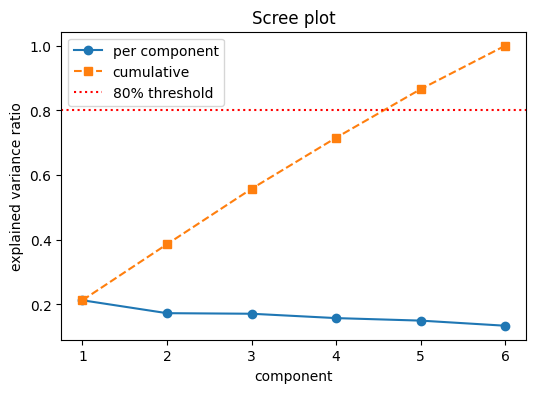

Minimum number of components for >= 80% variance: 5 (cumulative = 0.866)


In [10]:
Z = StandardScaler().fit_transform(df[num_cols])
pca = PCA().fit(Z)
evr = pca.explained_variance_ratio_
cum = np.cumsum(evr)

pca_table = pd.DataFrame({"explained variance ratio": evr, "cumulative": cum},
                         index=[f"PC{i+1}" for i in range(len(evr))])
display(pca_table.round(4))

plt.figure(figsize=(6, 4))
plt.plot(range(1, len(evr)+1), evr, "o-", label="per component")
plt.plot(range(1, len(evr)+1), cum, "s--", label="cumulative")
plt.axhline(0.8, color="red", ls=":", label="80% threshold")
plt.xlabel("component"); plt.ylabel("explained variance ratio"); plt.title("Scree plot"); plt.legend(); plt.show()

n80 = int(np.argmax(cum >= 0.80) + 1)
print("Minimum number of components for >= 80% variance:", n80, f"(cumulative = {cum[n80-1]:.3f})")

**Interpretation.** The variance is spread almost evenly (PC1 = 21.3%, PC2 = 17.3%, PC3 = 17.1%, PC4 = 15.8%, PC5 = 15.0%, PC6 = 13.4%); the scree plot has no clear "elbow". We need **5 components** to keep ≥ 80% of the variance (71.6% with 4, 86.6% with 5). This means the six numeric attributes are only weakly correlated with each other, so PCA cannot compress them much (only one dimension saved).

## Task 7. Kernel Functions
Same 10-row sample as in Task 3, standardized numeric attributes, γ = 0.5.

In [11]:
gamma = 0.5
X = Xs  # standardized 10 x 6 matrix from Task 3

K_linear = X @ X.T
sq_dists = np.sum(X**2, 1)[:, None] + np.sum(X**2, 1)[None, :] - 2 * X @ X.T
K_rbf = np.exp(-gamma * sq_dists)

print("Linear kernel K(x,x') = x^T x'"); display(as_df(K_linear).round(2))
print("RBF kernel K(x,x') = exp(-0.5 * ||x-x'||^2)"); display(as_df(K_rbf).round(3))

iu = np.triu_indices(10, 1)
k = np.argmax(sq_dists[iu]); i, j = int(iu[0][k]), int(iu[1][k])
print(f"Most different pair (largest squared distance): rows {i} and {j}")
print(f"  squared distance = {sq_dists[i, j]:.2f}")
print(f"  linear kernel    = {K_linear[i, j]:.3f}")
print(f"  RBF kernel       = {K_rbf[i, j]:.2e}")
print("\nRow vectors (standardized):"); display(pd.DataFrame(X[[i, j]], columns=num_cols, index=[i, j]).round(2))

Linear kernel K(x,x') = x^T x'


,0,1,2,3,4,5,6,7,8,9
0,3.17,2.28,-0.26,1.92,1.47,-1.24,-3.38,-4.30,-0.56,0.90
1,2.28,3.57,-0.25,2.54,-0.30,-1.58,-4.60,-6.90,-0.52,1.30
2,-0.26,-0.25,0.58,-0.03,0.28,-0.46,1.60,0.50,-0.19,-1.03
3,1.92,2.54,-0.03,2.04,0.62,-1.43,-3.02,-4.54,-0.14,0.76
4,1.47,-0.30,0.28,0.62,3.31,-0.70,0.63,1.88,0.78,-0.26
5,-1.24,-1.58,-0.46,-1.43,-0.70,1.92,0.79,3.42,0.68,0.84
6,-3.38,-4.60,1.60,-3.02,0.63,0.79,8.89,8.78,0.05,-3.85
7,-4.30,-6.90,0.50,-4.54,1.88,3.42,8.78,14.95,2.27,-1.68
8,-0.56,-0.52,-0.19,-0.14,0.78,0.68,0.05,2.27,1.31,0.84
9,0.90,1.30,-1.03,0.76,-0.26,0.84,-3.85,-1.68,0.84,2.62


RBF kernel K(x,x') = exp(-0.5 * ||x-x'||^2)


,0,1,2,3,4,5,6,7,8,9
0,1.000,0.337,0.118,0.502,0.170,0.023,0.000,0.000,0.061,0.136
1,0.337,1.000,0.098,0.765,0.024,0.013,0.000,0.000,0.052,0.166
2,0.118,0.098,1.000,0.261,0.189,0.181,0.044,0.001,0.321,0.072
3,0.502,0.765,0.261,1.000,0.128,0.033,0.000,0.000,0.162,0.207
4,0.170,0.024,0.189,0.128,1.000,0.036,0.004,0.001,0.218,0.040
5,0.023,0.013,0.181,0.033,0.036,1.000,0.010,0.007,0.391,0.238
6,0.000,0.000,0.044,0.000,0.004,0.010,1.000,0.043,0.006,0.000
7,0.000,0.000,0.001,0.000,0.001,0.007,0.043,1.000,0.003,0.000
8,0.061,0.052,0.321,0.162,0.218,0.391,0.006,0.003,1.000,0.324
9,0.136,0.166,0.072,0.207,0.040,0.238,0.000,0.000,0.324,1.000


Most different pair (largest squared distance): rows 1 and 7
  squared distance = 32.32
  linear kernel    = -6.901
  RBF kernel       = 9.58e-08

Row vectors (standardized):


,age,fnlwgt,educational-num,capital-gain,capital-loss,hours-per-week
1,0.31,-0.67,1.52,-0.15,-0.2,0.80
7,-1.38,1.89,-2.80,-0.15,-0.2,-1.26


**Interpretation.** The most different pair is **rows 1 and 7** (squared distance 32.3). Their linear kernel is **−6.90**, the most negative entry of the matrix, while their RBF kernel is **≈ 1e-7 ≈ 0**. The linear kernel is a dot product, so it measures direction and length: row 1 is above average in age, education and hours while row 7 is below average on all three, so the vectors point in opposite directions and the dot product is large and negative. The RBF kernel depends only on the distance and is bounded in (0, 1]: with γ = 0.5 the value exp(−16.2) is essentially 0, so it just says "very far apart / no similarity" and cannot distinguish "opposite" from "merely far".

## Task 8. Outlier Analysis
Attribute: `hours-per-week` (Z-score with |Z| > 3 vs. IQR method).

In [12]:
col = "hours-per-week"; h = df[col]

# Z-score method
z = (h - h.mean()) / h.std()
z_out = h[z.abs() > 3]
print(f"Mean = {h.mean():.2f}, std = {h.std():.2f}  ->  |Z|>3 means x < {h.mean()-3*h.std():.1f} or x > {h.mean()+3*h.std():.1f}")

# IQR method
Q1, Q3 = h.quantile(0.25), h.quantile(0.75); IQR = Q3 - Q1
lower, upper = Q1 - 1.5*IQR, Q3 + 1.5*IQR
iqr_out = h[(h < lower) | (h > upper)]
print(f"Q1 = {Q1}, Q3 = {Q3}, IQR = {IQR}, bounds = [{lower}, {upper}]")

print(f"\nOutliers flagged by Z-score: {len(z_out)}")
print(f"Outliers flagged by IQR:     {len(iqr_out)}")
only_iqr = sorted(set(iqr_out.index) - set(z_out.index))
only_z = sorted(set(z_out.index) - set(iqr_out.index))
print(f"Flagged by IQR only: {len(only_iqr)} rows (first 8 row indices: {only_iqr[:8]}, values {h.loc[only_iqr[:8]].tolist()})")
print(f"Flagged by Z-score only: {len(only_z)} rows")

Mean = 40.27, std = 12.10  ->  |Z|>3 means x < 4.0 or x > 76.6
Q1 = 40.0, Q3 = 45.0, IQR = 5.0, bounds = [32.5, 52.5]

Outliers flagged by Z-score: 57
Outliers flagged by IQR:     1355
Flagged by IQR only: 1298 rows (first 8 row indices: [4, 10, 11, 15, 19, 23, 26, 33], values [30, 70, 30, 60, 4, 60, 24, 75])
Flagged by Z-score only: 0 rows


In [13]:
# One global outlier: the largest value of hours-per-week
idx = h.idxmax()
print("Row", idx, "| hours-per-week =", h[idx], "| Z =", round(z[idx], 2))
df.loc[[idx], ["age", "workclass", "occupation", "education", "hours-per-week", "income"]]

Row 60 | hours-per-week = 99 | Z = 4.85


,age,workclass,occupation,education,hours-per-week,income
60,39,Private,Transport-moving,HS-grad,99,<=50K


**Interpretation.** The Z-score method flags **57** rows, the IQR method **1,355**. Every Z-score outlier is also an IQR outlier, so **no row is flagged only by Z-score**, while **1,298 rows are flagged only by IQR** (e.g. people working 30, 60 or 70 hours). The reason: most people work exactly 40 hours, so Q1 = 40 and Q3 = 45 and the IQR is only 5, giving narrow bounds [32.5, 52.5], whereas the standard deviation (12.1) is large, so |Z| > 3 only triggers beyond ≈ 4 or ≈ 77 hours.

**Global outlier example:** the row with 99 hours/week (Z ≈ 4.9, flagged by both methods). It is a *global* outlier because its value deviates strongly from the **whole** distribution of the attribute (far beyond 3σ, ~14 h every day) regardless of any context; it is not *contextual* (it does not look unusual only within a subgroup, e.g. only for one occupation or age), and it is not *collective* (it is a single record that is extreme on its own, not a group of records that are unusual only together).

## Defense notes (short)
- **Box plot algorithm:** Q1, Q3, IQR = Q3 − Q1; outlier if x < Q1 − 1.5·IQR or x > Q3 + 1.5·IQR.
- **Why z-score before distances:** puts attributes on the same scale (mean 0, std 1); raw `fnlwgt` would dominate everything.
- **Jaccard vs cosine:** Jaccard compares sets of shared categorical values; cosine compares the angle of numeric vectors (ignores length).
- **Pearson vs MI:** Pearson = linear only; MI = any dependence (including non-linear), always ≥ 0.
- **Chi-square (filter) vs Random Forest (embedded):** filter scores each feature independently of a model; embedded importance comes from a trained model.
- **PCA:** flat scree plot = weakly correlated attributes = little compression (5 of 6 components for 80%).
- **Linear vs RBF kernel:** linear = dot product (direction + length, can be negative); RBF = function of distance only, in (0, 1], local.
- **Z-score vs IQR outliers:** Z-score uses mean/std (sensitive to extremes, wide bounds); IQR uses quartiles (robust, narrow bounds when data is concentrated).